# pyrothermo examples

Needs `data/species.yaml` filled in from NIST. Species names below are the YAML keys; change them if you used different keys (e.g. `C_graphite`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from pyrothermo import Reaction, load_species

db = load_species()
sorted(db)

['C', 'CO', 'CO2', 'Fe', 'Fe2O3', 'Fe3O4', 'FeO', 'H2', 'H2O', 'O2']

## Cp of Fe across its phase changes

Dotted lines mark boundaries flagged as phase changes in the YAML (`transition: true` or a change of `phase`).

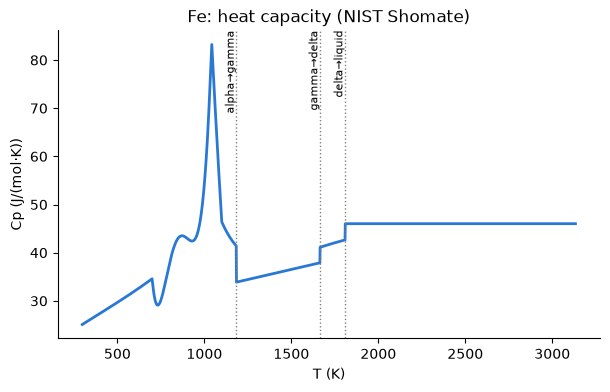

In [2]:
fe = db["Fe"]
T = np.linspace(fe.t_min, fe.t_max, 2000)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(T, fe.cp(T), lw=2, color="#2a78d6")
for Tt, below, above in fe.phase_transitions():
    ax.axvline(Tt, ls=":", color="gray", lw=1)
    ax.annotate(
        f"{below}→{above}", (Tt, ax.get_ylim()[1]), rotation=90, va="top", ha="right", fontsize=8
    )
ax.set(xlabel="T (K)", ylabel="Cp (J/(mol·K))", title="Fe: heat capacity (NIST Shomate)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## ΔG° of iron-oxide reduction reactions

Per mole of reaction as written. Standard states: pure solids, ideal gases at 1 bar.

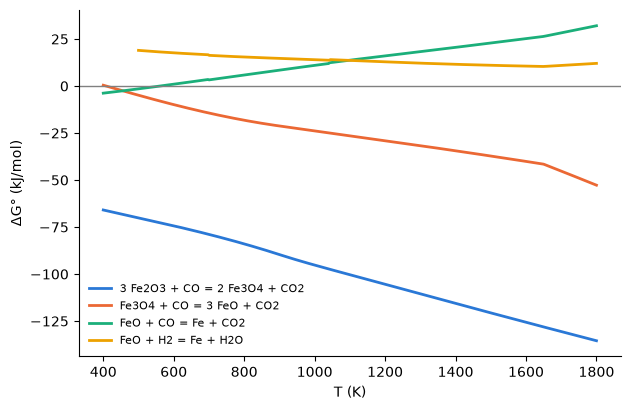

In [3]:
equations = [
    "3 Fe2O3 + CO = 2 Fe3O4 + CO2",
    "Fe3O4 + CO = 3 FeO + CO2",
    "FeO + CO = Fe + CO2",
    "FeO + H2 = Fe + H2O",
]
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(7, 4.5))
for eq, c in zip(equations, colors, strict=False):
    rx = Reaction.from_string(eq, db)
    lo, hi = rx.t_range
    T = np.linspace(max(lo, 400.0), min(hi, 1800.0), 500)
    ax.plot(T, rx.dG(T) / 1000, lw=2, color=c, label=str(rx))
ax.axhline(0, color="gray", lw=1)
ax.set(xlabel="T (K)", ylabel="ΔG° (kJ/mol)")
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [4]:
rx = Reaction.from_string("FeO + H2 = Fe + H2O", db)
for T in (900.0, 1100.0, 1300.0):
    print(f"{T:6.0f} K  dG = {rx.dG(T) / 1000:8.2f} kJ/mol   K = {rx.K(T):.4f}")

   900 K  dG =    14.69 kJ/mol   K = 0.1404
  1100 K  dG =    13.62 kJ/mol   K = 0.2256
  1300 K  dG =    12.17 kJ/mol   K = 0.3245


**Note.** In reality FeO is non-stoichiometric (wüstite) and is unstable below about 843 K (570 °C). This model treats each species as a pure phase.